# Eventuella avvikelser


,date,revenue,z_score,is_anomaly
56,2024-02-26,45538.28,4.083308,True
99,2024-04-09,39530.14,3.150218,True
158,2024-06-07,38232.87,2.948747,True


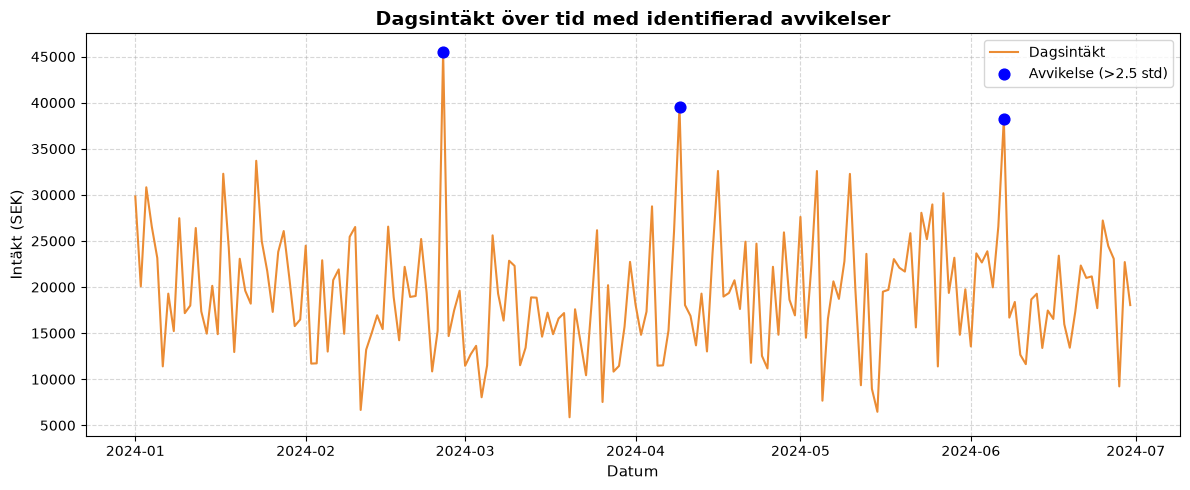

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

class SalesDataAnalyser:
    def __init__(self, filepath: str):
        self.df = pd.read_csv(filepath)
        self.df['date'] = pd.to_datetime(self.df['date'])
    def get_revenue_bounds(self, column: str = 'revenue', factor: float =1.5) -> tuple:
        q1 = self.df[column].quantile(0.25)
        q3 = self.df[column].quantile(0.75)
        iqr = q3 - q1
        lower_bounds = q1 - (factor * iqr)
        upper_bounds = q3 + (factor * iqr)
        
        return (lower_bounds, upper_bounds)
      
    def compute_anomalies(self, threshold_std: float = 2.5) -> pd.DataFrame:
        daily = self.df.groupby('date')['revenue'].sum().reset_index()
        mean_rev = np.mean(daily['revenue'])
        std_rev = np.std(daily['revenue'])

        daily['z_score'] = (daily['revenue'] - mean_rev) / std_rev
        daily['is_anomaly'] = np.abs(daily['z_score']) > threshold_std

        return daily
      
    def plot_anomalies(self, daily_df: pd.DataFrame, threshold_std: float = 2.5) -> None:
        fig, ax = plt.subplots(figsize=(12, 5))
        #Rita
        ax.plot(daily_df['date'], daily_df['revenue'], label='Dagsintäkt', color='#eb8c34', linewidth=1.5)
        #M, avvikelser
        anomalies = daily_df[daily_df['is_anomaly']]
        ax.scatter(anomalies['date'], anomalies['revenue'], color='blue', s=60, label=f'Avvikelse (>{threshold_std} std)', zorder=5)

        ax.set_title('Dagsintäkt över tid med identifierade avvikelser', fontsize=14, fontweight='bold')
        ax.set_xlabel('Datum', fontsize=11)
        ax.set_ylabel('Intäkt (SEK)', fontsize=11)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(loc='upper right')

        plt.tight_layout()
        plt.show()

analyser = SalesDataAnalyser('ecommerce_sales.csv')

lower, upper = analyser.get_revenue_bounds()

daily_df = analyser.compute_anomalies(threshold_std=2.5)

display(daily_df[daily_df['is_anomaly']])

analyser.plot_anomalies(daily_df)